# Máscaras binarias de peces con SAM2 (a partir de las bounding boxes)

Genera, para cada bbox de pez del dataset Roboflow (`datasets_roboflow/fish market.v1i.coco`), una **máscara binaria** usando **SAM2.1-base** con la bbox como *prompt*. Las máscaras servirán luego para entrenar **YOLO-seg** (supraclase `pez`, instancias).

**Reglas de selección**
- Hasta `MAX_PER_CLASS` (250) recortes **efectivos** por especie. Se recorre primero `train`; si faltan, se completa con `valid`. Si una especie no llega a la cuota, se usa todo lo disponible.
- Un recorte descartado por baja calidad **no cuenta** para la cuota: se sigue con el siguiente hasta tener `MAX_PER_CLASS` máscaras buenas.
- La especie sale de `category_id`. Se verifica contra el nombre del archivo (`Magur59.jpg` → `magur`); si no coinciden, la anotación se omite por ambigua.
- SAM2 recibe la **imagen completa** + la bbox (más contexto que el recorte). Una imagen con varios peces se procesa en una sola pasada y cada bbox es un ejemplo independiente.

**Salida** (todo en un único split) en `datasets_roboflow/fish_sam2_masks/`:
`images/` · `masks/` (PNG 0/255, tamaño de la imagen) · `rejected_masks/` · `annotations.csv` · `annotations.json` · `rejected.csv`

## Criterio de confianza
Una máscara se acepta solo si cumple **todas** estas condiciones (umbrales editables en la config):

| Métrica | Qué mide | Umbral |
|---|---|---|
| `sam_score` | IoU predicho por la propia SAM2 (autoevaluación del decoder) | ≥ 0.85 |
| `box_iou` | IoU entre la bbox ajustada de la máscara y la bbox GT. Detecta máscaras que cubren solo una parte del pez o que se escapan | ≥ 0.50 (las bboxes de Roboflow son holgadas; con 0.80 se rechazaban máscaras correctas) |
| `inside_ratio` | fracción de píxeles de la máscara dentro de la bbox. Detecta fugas al fondo/otros peces | ≥ 0.90 |
| `fill_ratio` | área máscara / área bbox. Descarta máscaras casi vacías o que llenan toda la caja | 0.15 – 0.95 |
| `cc_share` | fracción del área en la mayor componente conexa. Descarta máscaras fragmentadas | ≥ 0.90 |

`sam_score` sola no alcanza (SAM suele ser optimista); las métricas geométricas contra la bbox GT aportan una verificación independiente. A las máscaras aceptadas se les deja solo la mayor componente conexa y se rellenan huecos.

In [1]:
import json, re, shutil, random, time
from pathlib import Path
import numpy as np, cv2, pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from scipy import ndimage as ndi
from ultralytics import SAM

# ---------------- Config ----------------
MAX_PER_CLASS = 250                  # máscaras buenas por especie
SPLITS = ['train', 'valid']          # orden de prioridad
SEED = 0
SAM_WEIGHTS = 'sam2.1_b.pt'

MIN_BOX_SIDE = 16                    # px; bboxes más chicas se ignoran
MIN_SAM_SCORE = 0.85
MIN_BOX_IOU = 0.50
MIN_INSIDE = 0.90
FILL_RANGE = (0.15, 0.95)
MIN_CC_SHARE = 0.90

ROOT = Path('datasets_roboflow/fish market.v1i.coco')
OUT = Path('datasets_roboflow/fish_sam2_masks')
RESET = False                        # True: borra OUT y arranca de cero (usar si cambiás umbrales)

if RESET and OUT.exists(): shutil.rmtree(OUT)
for d in ('images', 'masks', 'rejected_masks'): (OUT / d).mkdir(parents=True, exist_ok=True)

## 1. Candidatos
Se leen los COCO json y se arma la lista de anotaciones por imagen, mezcladas con semilla dentro de cada split (train antes que valid).

In [2]:
norm = lambda s: re.sub(r'[\s_]+', '', s.lower())

images, cats = {}, {}      # images[(split, image_id)] -> dict ; cats[id] -> nombre
order = []                 # [(split, image_id)] en orden de procesamiento
anns_by_img = {}
n_name_mismatch = 0
rng = random.Random(SEED)

for split in SPLITS:
    coco = json.load(open(ROOT / split / '_annotations.coco.json', encoding='utf-8'))
    cats = {c['id']: c['name'] for c in coco['categories'] if c['id'] != 0}   # 0 = 'fish' (padre)
    ids = []
    for im in coco['images']:
        images[(split, im['id'])] = im
        ids.append(im['id'])
    for a in coco['annotations']:
        if a['category_id'] not in cats: continue
        im = images[(split, a['image_id'])]
        stem = re.sub(r'\d+$', '', Path(im['extra']['name']).stem)       # 'Magur59' -> 'Magur'
        a['species_from_filename'] = stem
        if norm(stem) != norm(cats[a['category_id']]):
            n_name_mismatch += 1; continue
        if min(a['bbox'][2:]) < MIN_BOX_SIDE: continue
        anns_by_img.setdefault((split, a['image_id']), []).append(a)
    rng.shuffle(ids)
    order += [(split, i) for i in ids if (split, i) in anns_by_img]

avail = pd.Series([cats[a['category_id']] for v in anns_by_img.values() for a in v]).value_counts()
print(f'imágenes candidatas: {len(order)} | anotaciones omitidas por nombre≠categoría: {n_name_mismatch}')
print('anotaciones disponibles por especie (train+valid):'); print(avail.to_string())

imágenes candidatas: 17447 | anotaciones omitidas por nombre≠categoría: 12
anotaciones disponibles por especie (train+valid):
rui           1972
taki          1634
aair          1363
mrigel        1344
pabda         1294
katla         1272
boal          1213
puti          1176
shol          1040
tara baim      804
ilish          761
kal baush      728
pangas         702
koi            611
foli           459
magur          435
chapila        319
deshi puti     314
telapiya       109
tengra          91
shor puti       33


## 2. SAM2 y métricas de calidad

In [3]:
model = SAM(SAM_WEIGHTS)

def xywh2xyxy(b): return [b[0], b[1], b[0] + b[2], b[1] + b[3]]

def clean_mask(m):
    # deja la mayor componente conexa y rellena huecos
    lab, n = ndi.label(m)
    if n == 0: return m, 0.0
    sizes = ndi.sum(m, lab, range(1, n + 1))
    k = int(np.argmax(sizes)) + 1
    return ndi.binary_fill_holes(lab == k), float(sizes[k - 1] / sizes.sum())

def evaluate(mask, score, bbox_xywh):
    # devuelve (mascara_limpia, dict de métricas, motivo de rechazo | None)
    area_raw = int(mask.sum())
    if area_raw == 0:
        return mask, dict(sam_score=float(score), box_iou=0., inside_ratio=0., fill_ratio=0., cc_share=0., mask_area=0), 'mask_vacia'
    x1, y1, x2, y2 = xywh2xyxy(bbox_xywh)
    ys, xs = np.where(mask)
    mx1, my1, mx2, my2 = xs.min(), ys.min(), xs.max() + 1, ys.max() + 1
    inter = max(0, min(x2, mx2) - max(x1, mx1)) * max(0, min(y2, my2) - max(y1, my1))
    box_area = (x2 - x1) * (y2 - y1)
    box_iou = inter / (box_area + (mx2 - mx1) * (my2 - my1) - inter)
    inside = mask[max(int(np.floor(y1)), 0):int(np.ceil(y2)), max(int(np.floor(x1)), 0):int(np.ceil(x2))].sum() / area_raw
    clean, cc_share = clean_mask(mask)
    area = int(clean.sum())
    fill = area / box_area
    met = dict(sam_score=float(score), box_iou=float(box_iou), inside_ratio=float(inside),
               fill_ratio=float(fill), cc_share=cc_share, mask_area=area)
    reason = None
    if score < MIN_SAM_SCORE: reason = 'sam_score'
    elif box_iou < MIN_BOX_IOU: reason = 'box_iou'
    elif inside < MIN_INSIDE: reason = 'inside_ratio'
    elif not (FILL_RANGE[0] <= fill <= FILL_RANGE[1]): reason = 'fill_ratio'
    elif cc_share < MIN_CC_SHARE: reason = 'cc_share'
    return clean, met, reason

## 3. Generación
Se procesa imagen por imagen; una especie deja de pedirse cuando llega a `MAX_PER_CLASS` o se le acaban los candidatos. El proceso es **reanudable**: lo ya procesado queda en `*.jsonl` y se saltea si se vuelve a ejecutar (con los mismos umbrales).

In [4]:
acc_path, rej_path = OUT / 'accepted.jsonl', OUT / 'rejected.jsonl'
load = lambda p: [json.loads(l) for l in open(p, encoding='utf-8')] if p.exists() else []
accepted, rejected = load(acc_path), load(rej_path)
done = {(r['split'], r['ann_id']) for r in accepted + rejected}
count = {sp: n for sp, n in pd.Series([r['species'] for r in accepted], dtype=object).value_counts().items()}
remaining = {}                                    # candidatos aún no procesados por especie
for (split, _), v in anns_by_img.items():
    for a in v:
        if (split, a['id']) not in done:
            remaining[cats[a['category_id']]] = remaining.get(cats[a['category_id']], 0) + 1

def active(sp): return count.get(sp, 0) < MAX_PER_CLASS and remaining.get(sp, 0) > 0

used_names = {r['image'] for r in accepted}
t0 = time.time()
fa, fr = open(acc_path, 'a', encoding='utf-8'), open(rej_path, 'a', encoding='utf-8')
pbar = tqdm(order, desc='imágenes')
for key in pbar:
    if not any(active(s) for s in cats.values()): break
    split, _ = key
    todo = [a for a in anns_by_img[key] if (split, a['id']) not in done]
    for a in todo: remaining[cats[a['category_id']]] -= 1
    todo = [a for a in todo if count.get(cats[a['category_id']], 0) < MAX_PER_CLASS]
    if not todo: continue
    im = images[key]
    src = ROOT / split / im['file_name']
    res = model(str(src), bboxes=[xywh2xyxy(a['bbox']) for a in todo], verbose=False)[0]
    masks = res.masks.data.cpu().numpy().astype(bool)
    scores = res.boxes.conf.cpu().numpy()
    stem = Path(im['file_name']).stem
    for a, m, s in zip(todo, masks, scores):
        sp = cats[a['category_id']]
        if count.get(sp, 0) >= MAX_PER_CLASS: continue          # cuota alcanzada dentro de la misma imagen
        clean, met, reason = evaluate(m, s, a['bbox'])
        base = dict(split=split, ann_id=a['id'], category_id=a['category_id'], species=sp,
                    bbox_xywh=a['bbox'], img_w=im['width'], img_h=im['height'], **met)
        mname = f'{stem}__ann{a["id"]}.png'
        if reason:
            cv2.imwrite(str(OUT / 'rejected_masks' / f'{split}_{mname}'), clean.astype(np.uint8) * 255)
            r = dict(base, orig_image=f'{split}/{im["file_name"]}', reason=reason, mask=f'rejected_masks/{split}_{mname}')
            rejected.append(r); fr.write(json.dumps(r) + '\n')
        else:
            iname = im['file_name'] if im['file_name'] not in used_names else f'{split}_{im["file_name"]}'
            if not (OUT / 'images' / iname).exists(): shutil.copy2(src, OUT / 'images' / iname)
            used_names.add(iname)
            cv2.imwrite(str(OUT / 'masks' / mname), clean.astype(np.uint8) * 255)
            r = dict(base, image=iname, mask=f'masks/{mname}', species_from_filename=a['species_from_filename'])
            accepted.append(r); fa.write(json.dumps(r) + '\n')
            count[sp] = count.get(sp, 0) + 1
        done.add((split, a['id']))
    fa.flush(); fr.flush()
    pbar.set_postfix(ok=len(accepted), rej=len(rejected))
fa.close(); fr.close()
print(f'listo en {time.time() - t0:.0f}s | aceptadas: {len(accepted)} | rechazadas: {len(rejected)}')

imágenes:   0%|          | 0/17447 [00:00<?, ?it/s]

listo en 2920s | aceptadas: 4729 | rechazadas: 43


## 4. Exportar CSV / JSON y resumen

In [5]:
df = pd.DataFrame(accepted)
df['x'], df['y'], df['w'], df['h'] = zip(*df['bbox_xywh'])
cols = ['image', 'mask', 'split', 'ann_id', 'species', 'category_id', 'x', 'y', 'w', 'h', 'img_w', 'img_h',
        'sam_score', 'box_iou', 'inside_ratio', 'fill_ratio', 'cc_share', 'mask_area']
df = df.sort_values(['species', 'image'])[cols].rename(columns={'split': 'origin_split'})
df.to_csv(OUT / 'annotations.csv', index=False)

js = {}                                            # agrupado por imagen (puede haber varios peces)
for r in df.to_dict('records'):
    e = js.setdefault(r['image'], dict(image=r['image'], width=r['img_w'], height=r['img_h'],
                                       origin_split=r['origin_split'], objects=[]))
    e['objects'].append(dict(mask=r['mask'], species=r['species'], category_id=r['category_id'],
                             bbox_xywh=[r['x'], r['y'], r['w'], r['h']], sam_score=r['sam_score'],
                             box_iou=r['box_iou'], inside_ratio=r['inside_ratio'], fill_ratio=r['fill_ratio']))
json.dump(list(js.values()), open(OUT / 'annotations.json', 'w', encoding='utf-8'), indent=1)
rdf = pd.DataFrame(rejected)
rdf.to_csv(OUT / 'rejected.csv', index=False)

summ = pd.DataFrame({'disponibles': avail, 'aceptadas': df['species'].value_counts()})
summ['desde_train'] = df[df.origin_split == 'train']['species'].value_counts()
summ['desde_valid'] = df[df.origin_split == 'valid']['species'].value_counts()
summ['rechazadas'] = rdf['species'].value_counts() if len(rdf) else 0
summ = summ.fillna(0).astype(int)
summ['tasa_rechazo'] = (summ.rechazadas / (summ.aceptadas + summ.rechazadas).clip(lower=1)).round(2)
display(summ.sort_values('aceptadas'))
print(f'{len(df)} máscaras en {df.image.nunique()} imágenes')
if len(rdf): display(rdf['reason'].value_counts().rename('motivo de rechazo (primera condición que falló)'))

,disponibles,aceptadas,desde_train,desde_valid,rechazadas,tasa_rechazo
shor puti,33,33,27,6,0,0.00
tengra,91,87,39,48,4,0.04
telapiya,109,109,63,46,0,0.00
aair,1363,250,250,0,7,0.03
foli,459,250,250,0,0,0.00
boal,1213,250,250,0,0,0.00
chapila,319,250,250,0,0,0.00
deshi puti,314,250,250,0,0,0.00
koi,611,250,250,0,0,0.00
magur,435,250,250,0,3,0.01


4729 máscaras en 4729 imágenes


reason
fill_ratio    31
sam_score     10
box_iou        2
Name: motivo de rechazo (primera condición que falló), dtype: int64

## 5. Inspección visual
Controlá a ojo antes de entrenar. Si las rechazadas se ven bien (umbrales muy estrictos) o las aceptadas se ven mal, ajustá los umbrales y volvé a correr con `RESET = True`.

Una aceptada al azar por especie


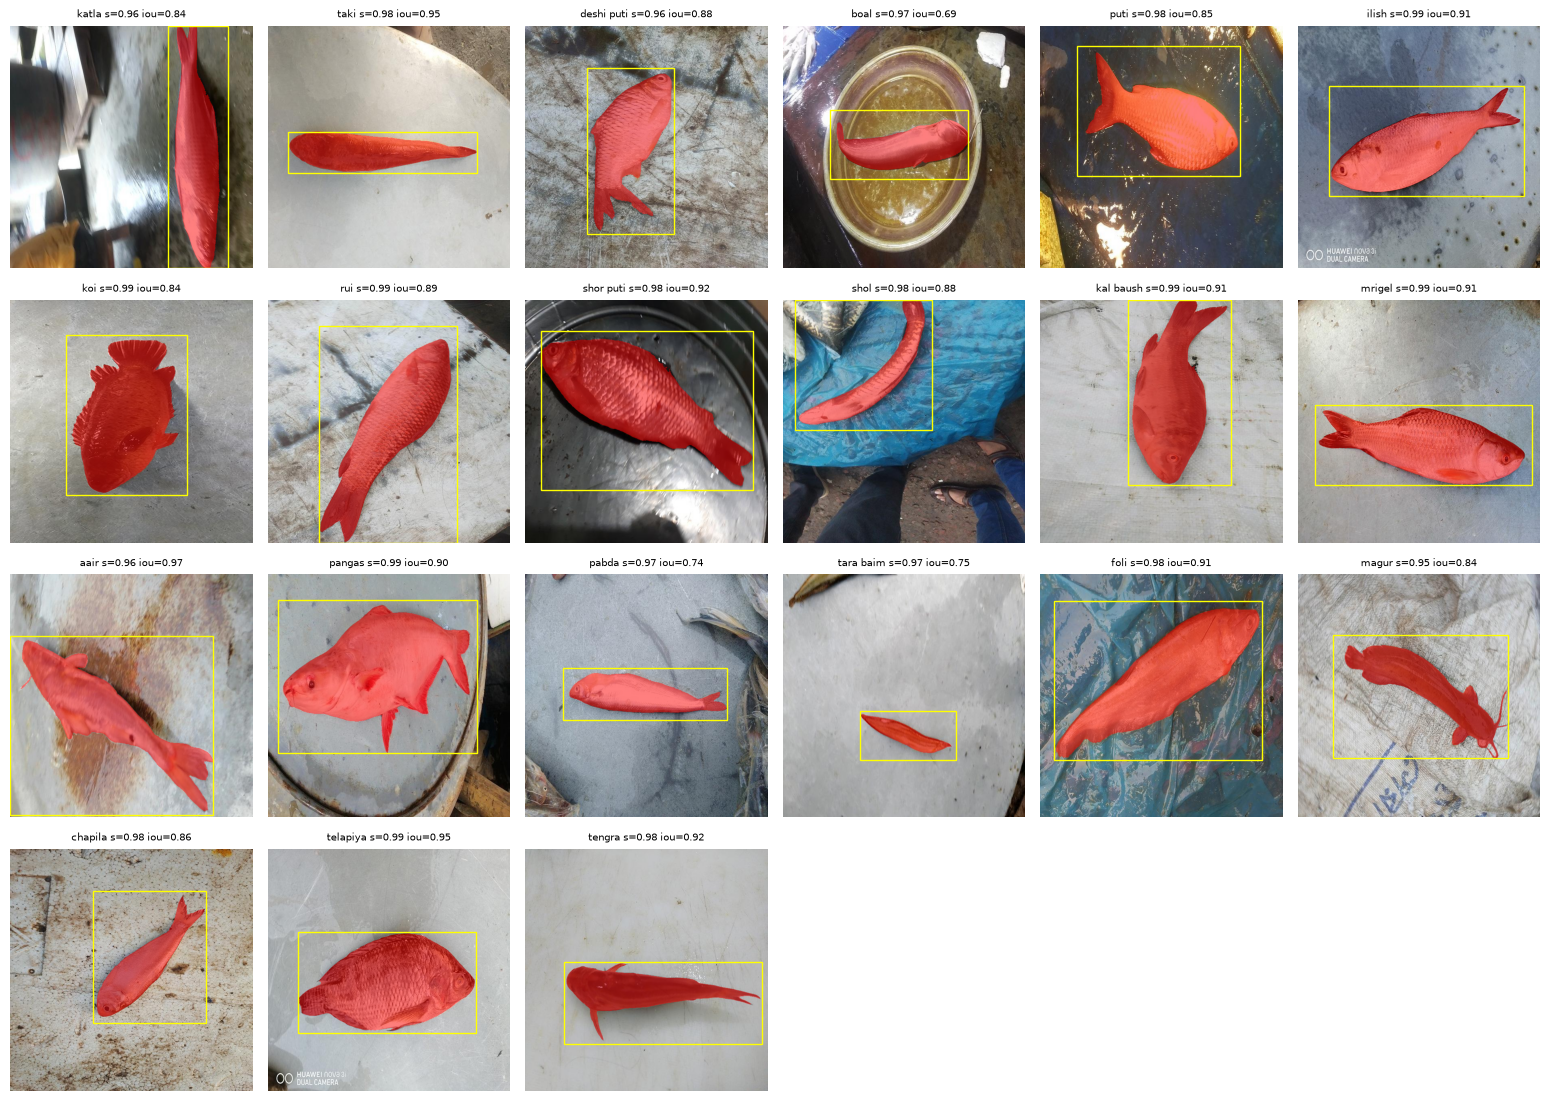

Rechazadas al azar (para revisar umbrales)


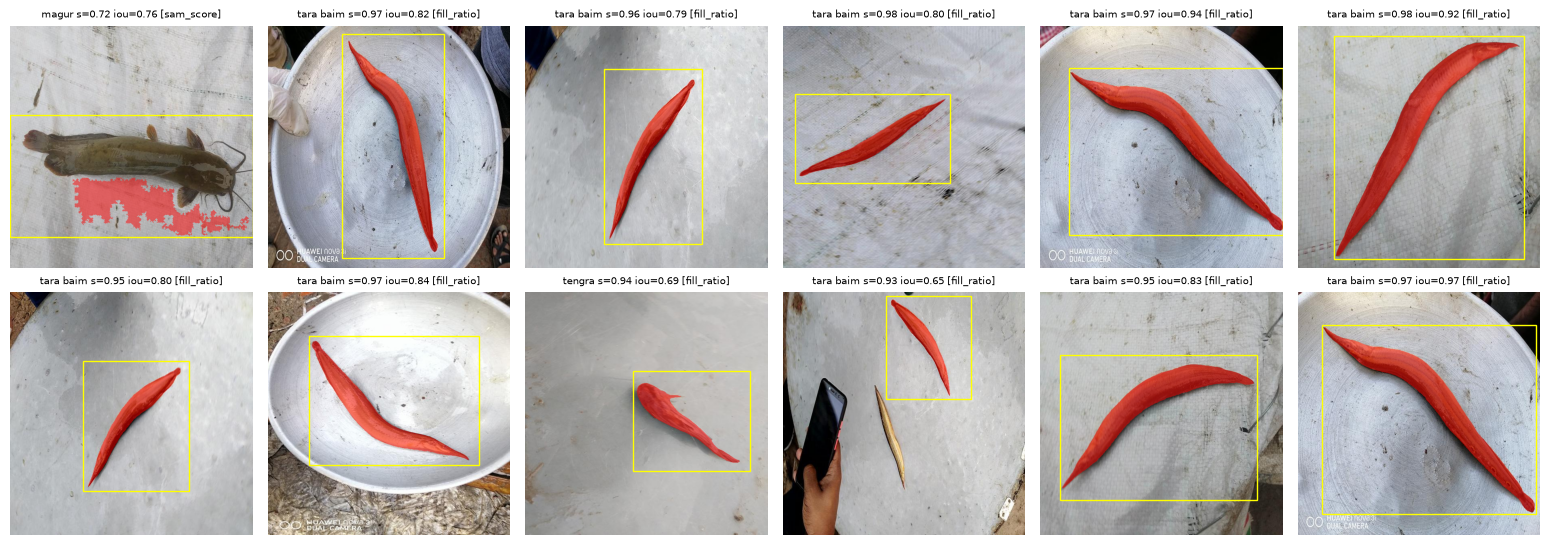

In [6]:
def show(rows, n_cols=6):
    n_rows = int(np.ceil(len(rows) / n_cols))
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(2.6 * n_cols, 2.8 * n_rows), squeeze=False)
    for ax in axs.ravel(): ax.axis('off')
    for ax, r in zip(axs.ravel(), rows):
        src = OUT / 'images' / r['image'] if 'image' in r else ROOT / r['orig_image']
        img = cv2.cvtColor(cv2.imread(str(src)), cv2.COLOR_BGR2RGB)
        m = cv2.imread(str(OUT / r['mask']), 0) > 0
        img[m] = (0.5 * img[m] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
        x, y, w, h = r['bbox_xywh']
        ax.imshow(img); ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, ec='yellow', lw=1))
        ax.set_title(f"{r['species']} s={r['sam_score']:.2f} iou={r['box_iou']:.2f}" + (f" [{r['reason']}]" if 'reason' in r else ''), fontsize=7)
    plt.tight_layout(); plt.show()

print('Una aceptada al azar por especie')
show([r for r in accepted if r['ann_id'] in set(
    df.groupby('species').sample(1, random_state=SEED).ann_id)])
if len(rdf):
    print('Rechazadas al azar (para revisar umbrales)')
    show(rdf.sample(min(12, len(rdf)), random_state=SEED).to_dict('records'))

In [1]:
# ===== Split train/val/test 70/15/15 estratificado por especie (celda independiente) =====
# Lee lo generado en fish_sam2_masks/ (annotations.csv + images/ + masks/) y arma un dataset YOLO-seg:
#   SPLIT_OUT/images/{train,val,test}/  y  SPLIT_OUT/labels/{train,val,test}/   (labels = polígonos normalizados, clase 0 = pez)
import shutil, random
from pathlib import Path
import cv2, numpy as np, pandas as pd

SRC = Path('datasets_roboflow/fish_sam2_masks')
SPLIT_OUT = Path('datasets_roboflow/fish_sam2_masks_split')
RATIOS = {'train': 0.70, 'val': 0.15, 'test': 0.15}
SEED = 0
POLY_EPS = 0.002                     # simplificación del contorno (fracción del perímetro)
RESET_SPLIT = True                   # borra SPLIT_OUT antes de generar

if RESET_SPLIT and SPLIT_OUT.exists(): shutil.rmtree(SPLIT_OUT)
for kind in ('images', 'labels'):
    for sp in RATIOS: (SPLIT_OUT / kind / sp).mkdir(parents=True, exist_ok=True)

ann = pd.read_csv(SRC / 'annotations.csv')
rng = random.Random(SEED)

# 1) reparto por imagen, dentro de cada especie (una imagen = una unidad, nunca queda en dos splits)
assign = {}
for species, g in ann.groupby('species'):
    imgs = sorted(g['image'].unique()); rng.shuffle(imgs)
    n = len(imgs)
    n_val, n_test = round(n * RATIOS['val']), round(n * RATIOS['test'])
    n_val, n_test = (max(n_val, 1), max(n_test, 1)) if n >= 3 else (0, 0)
    for i, im in enumerate(imgs):
        assign[im] = 'test' if i < n_test else 'val' if i < n_test + n_val else 'train'
ann['split'] = ann['image'].map(assign)

# 2) máscara -> polígono YOLO-seg
def mask_to_yolo(mask_path, w, h):
    m = (cv2.imread(str(mask_path), 0) > 0).astype(np.uint8)
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not cnts: return None
    c = max(cnts, key=cv2.contourArea)
    c = cv2.approxPolyDP(c, POLY_EPS * cv2.arcLength(c, True), True).reshape(-1, 2)
    if len(c) < 3: return None
    pts = (c / [w, h]).clip(0, 1).ravel()
    return '0 ' + ' '.join(f'{p:.6f}' for p in pts)

n_skip = 0
for im, g in ann.groupby('image'):
    sp, species = g['split'].iloc[0], g['species'].iloc[0]
    lines = [l for r in g.itertuples() if (l := mask_to_yolo(SRC / r.mask, r.img_w, r.img_h))]
    if not lines: n_skip += 1; continue
    name = f'{species}__{im}'.replace(' ', '_')
    shutil.copy2(SRC / 'images' / im, SPLIT_OUT / 'images' / sp / name)
    (SPLIT_OUT / 'labels' / sp / (Path(name).stem + '.txt')).write_text('\n'.join(lines) + '\n')

(SPLIT_OUT / 'data.yaml').write_text(
    f"path: {SPLIT_OUT.resolve().as_posix()}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n  0: pez\n")
ann[['image', 'species', 'split']].drop_duplicates().to_csv(SPLIT_OUT / 'split.csv', index=False)

tab = ann.drop_duplicates('image').pivot_table(index='species', columns='split', values='image', aggfunc='count', fill_value=0)[list(RATIOS)]
tab['total'] = tab.sum(axis=1)
tab.loc['TOTAL'] = tab.sum()
display(tab)
print(f'imágenes sin polígono válido omitidas: {n_skip} | salida: {SPLIT_OUT}')

split,train,val,test,total
species,,,,
aair,174,38,38,250
boal,174,38,38,250
chapila,174,38,38,250
deshi puti,174,38,38,250
foli,174,38,38,250
ilish,174,38,38,250
kal baush,174,38,38,250
katla,174,38,38,250
koi,174,38,38,250


imágenes sin polígono válido omitidas: 0 | salida: datasets_roboflow\fish_sam2_masks_split
